<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 0. Settings
Signal QC of all 60 final sessions (from 01_sessions_setup: final_sessions.csv), both references (original, CMR).
Known bad channels (removed in preprocessing + extra_bad_channels.csv) are left out before the CMR.
Shared functions in main\functions.py (imported as fn). RUN = False in the loop: nothing is computed until it is switched on.
Per-session results -> 2_processed\<session>\amir_data\QC; summary tables -> main\tables; figures -> main\figures\04_QC.

<div>

In [3]:
# %%
# ── 0. SETTINGS ──
import os, sys, importlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAIN      = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)                                   # picks up changes in functions.py without restarting

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
PROC      = os.path.join(DATA_ROOT, "2_processed")
AMIR      = os.path.join(DATA_ROOT, "amir_data")
TABLES    = os.path.join(MAIN, "tables")
FIGS      = os.path.join(MAIN, "figures", "04_QC")
SUB       = os.path.join("amir_data", "down_sampled", "1000_Hz")
QC_SUB    = os.path.join("amir_data", "QC")              # per-session QC files
os.makedirs(FIGS, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
XB    = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))          # read only here
REFS  = ["original", "CMR"]

print(f"final sessions: {len(final)} | extra bad channel rows: {len(XB)} | functions.py loaded from {fn.__file__}")

final sessions: 60 | extra bad channel rows: 107 | functions.py loaded from C:\Users\ar687\Documents\GitHub\AmirAnalysis\main\functions.py


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 1. Load one session (test)
fn.load_session: 1000 Hz recording (channels removed in preprocessing already missing) minus the session's extra bad channels
(extra_bad_channels.csv), plus the CMR version (global median, on the fly). fn.probe_table: position and shank of each channel.
Test on the two pilots: 136_0529 (only AP138 removed in preprocessing, no extra) and 135_0529 (7 in preprocessing + AP362, AP381).

<div>

In [5]:
# %%
# ── 1. LOAD ONE SESSION (test on the two pilots) ──
importlib.reload(fn)
for s in ["20260529_r0000136_wt_1318", "20260529_r0000135_wt_1411"]:
    recs, removed = fn.load_session(PROC, s, XB)
    pdf = fn.probe_table(recs["original"])
    print(f"{s}: channels {recs['original'].get_num_channels()} (original) / {recs['CMR'].get_num_channels()} (CMR) "
          f"| extra bad removed: {removed} | fs {recs['original'].get_sampling_frequency():.0f} Hz "
          f"| {recs['original'].get_total_duration() / 60:.1f} min | shanks: {pdf['shank'].value_counts().sort_index().to_dict()}")

20260529_r0000136_wt_1318: channels 383 (original) / 383 (CMR) | extra bad removed: [] | fs 1000 Hz | 32.1 min | shanks: {0: 119, 1: 187, 2: 77}
20260529_r0000135_wt_1411: channels 375 (original) / 375 (CMR) | extra bad removed: ['imec0.ap#AP362', 'imec0.ap#AP381'] | fs 1000 Hz | 41.2 min | shanks: {0: 28, 1: 201, 2: 146}


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 2. PSD per channel (test on one session)
fn.compute_psd: Welch PSD per channel from 30 pieces of 10 s spread over the whole recording (2 s windows, 0.5 Hz, 1–100 Hz).
fn.psd_table: per channel log10 power per band (delta 1–3, theta 4–7, alpha 8–12, beta 13–29, low gamma 30–60, high gamma 61–100),
broadband power, and the 50 Hz line ratio (49–51 Hz vs 45–48 + 52–55 Hz; ~1 or below = notch worked).
Both references. Test session: 20260529_r0000136_wt_1318 (pilot; earlier result: 50 Hz fine).

<div>

In [3]:
# %%
# ── 2. PSD PER CHANNEL (test on one session; the loop over all sessions is step 4) ──
importlib.reload(fn)
TEST = "20260529_r0000136_wt_1318"
recs, removed = fn.load_session(PROC, TEST, XB)
pdf = fn.probe_table(recs["original"])
psd, qc = {}, {}
for ref in REFS:
    freqs, psd[ref], ids = fn.compute_psd(recs[ref])
    qc[ref] = fn.psd_table(freqs, psd[ref], ids, pdf)
    print(f"{ref:8s}: {len(ids)} channels | freqs {freqs[0]:.1f}–{freqs[-1]:.1f} Hz ({len(freqs)} bins) | "
          f"50 Hz ratio median {qc[ref]['line_ratio'].median():.2f}, max {qc[ref]['line_ratio'].max():.2f} | "
          f"median log broadband {qc[ref]['log_broadband'].median():.2f}")

original: 383 channels | freqs 1.0–100.0 Hz (199 bins) | 50 Hz ratio median 0.21, max 0.23 | median log broadband 1.73
CMR     : 383 channels | freqs 1.0–100.0 Hz (199 bins) | 50 Hz ratio median 0.23, max 0.26 | median log broadband 1.30


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 3. Single bad channels + 50 Hz check (test on one session)
fn.flag_channels_local: each channel's broadband power vs the median of its neighbours on the same shank (±75 µm, >= 3 neighbours);
flagged if |Δlog10| > 0.3 (factor 2). Depth blocks are not flagged, only lone odd channels.
50 Hz: flagged if line_ratio > 1 (more power at 49–51 Hz than next to it = notch did not remove the line).
Earlier result for 20260529_r0000136_wt_1318 (2026-10-19): original 0 outliers; CMR 3 (AP17, AP324, AP326, ~2.5x more power), kept.

<div>

In [4]:
# %%
# ── 3. SINGLE BAD CHANNELS + 50 Hz (test session from step 2) ──
importlib.reload(fn)
for ref in REFS:
    loc = fn.flag_channels_local(qc[ref], radius_um=75, thr_log=0.3)
    line = qc[ref][qc[ref]["line_ratio"] > 1]
    print(f"\n{ref}: {len(loc)} local outliers | {len(line)} channels with 50 Hz line ratio > 1")
    if len(loc):
        print(loc[["channel_id", "shank", "y", "local_dev"]].round(2).to_string(index=False))
    if len(line):
        print(line[["channel_id", "shank", "y", "line_ratio"]].round(2).to_string(index=False))


original: 0 local outliers | 0 channels with 50 Hz line ratio > 1

CMR: 3 local outliers | 0 channels with 50 Hz line ratio > 1
    channel_id  shank      y  local_dev
 imec0.ap#AP17      0 3000.0       0.42
imec0.ap#AP324      1 2070.0       0.40
imec0.ap#AP326      1 2085.0       0.40


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 4. Signal QC of all final sessions (loop)
Per session: fn.load_session (minus extra bad channels) -> fn.qc_session for original and CMR
(PSD 30 x 10 s, band powers, 50 Hz ratio, local_dev vs neighbours ±75 µm).
Saved per session: 2_processed\<session>\amir_data\QC\psd.npz (freqs, PSD per reference, channel ids) and qc_channels.csv.
All sessions together: tables\qc_channels_all.csv (one row per session x reference x channel).
RUN = False: only reports which sessions are done. Sessions with a finished QC file are skipped (OVERWRITE = True to redo).
Estimated time: ~1–2 min per session (not measured), ~1–2 h for 60 sessions.

<div>

In [6]:
# %%
# ── 4. SIGNAL QC OF ALL FINAL SESSIONS (loop) ──
importlib.reload(fn)
RUN, OVERWRITE = True, False
ERR_LOG = os.path.join(TABLES, "qc_errors.csv")

def qc_files(s):
    d = os.path.join(PROC, s, QC_SUB)
    return d, os.path.join(d, "psd.npz"), os.path.join(d, "qc_channels.csv")

done = [s for s in final["session"] if os.path.exists(qc_files(s)[2])]
todo = [s for s in final["session"] if OVERWRITE or s not in done]
print(f"final sessions: {len(final)} | QC done: {len(done)} | to do: {len(todo)}")

if RUN:
    t_all = time.time() if "time" in globals() else None
    import time
    t_all = time.time()
    for i, s in enumerate(todo, 1):
        t0 = time.time()
        try:
            recs, removed = fn.load_session(PROC, s, XB)
            pdf = fn.probe_table(recs["original"])
            freqs, psd, tab = fn.qc_session(recs, pdf)
            tab.insert(0, "session", s); tab.insert(1, "rat", final.set_index("session").loc[s, "rat"])
            d, f_npz, f_csv = qc_files(s)
            os.makedirs(d, exist_ok=True)
            np.savez_compressed(f_npz, freqs=freqs, channel_ids=np.array(pdf["channel_id"]),
                                **{f"psd_{r}": p for r, p in psd.items()})
            tab.to_csv(f_csv, index=False)                                   # written last = session finished
            n_out = tab.groupby("ref")["flag_local"].sum().to_dict()
            print(f"[{i}/{len(todo)}] {s}: {(time.time() - t0) / 60:.1f} min | local outliers {n_out} | "
                  f"max 50 Hz ratio {tab['line_ratio'].max():.2f}", flush=True)
        except Exception as e:                                               # one broken session does not stop the run
            print(f"[{i}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
            pd.DataFrame([{"session": s, "error": repr(e)}]).to_csv(
                ERR_LOG, mode="a", header=not os.path.exists(ERR_LOG), index=False)
    print(f"\nfinished in {(time.time() - t_all) / 60:.0f} min")

# collect all finished sessions into one table (also when RUN = False)
parts = [pd.read_csv(qc_files(s)[2], dtype={"rat": str}) for s in final["session"] if os.path.exists(qc_files(s)[2])]
if parts:
    QC = pd.concat(parts, ignore_index=True)
    QC.to_csv(os.path.join(TABLES, "qc_channels_all.csv"), index=False)
    print(f"qc_channels_all.csv: {QC['session'].nunique()} sessions, {len(QC)} rows")
else:
    print("no QC results yet (RUN = False)")

final sessions: 60 | QC done: 60 | to do: 0

finished in 0 min
qc_channels_all.csv: 60 sessions, 45376 rows


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 5. QC summary (all final sessions)
From tables\qc_channels_all.csv (step 4). Per session and reference: channels, local outliers (|Δlog10| > 0.3 vs neighbours),
channels with 50 Hz ratio > 1, median 50 Hz ratio. Per rat: sums. Repeat offenders: per rat and reference, readout channels (AP number)
and electrode positions (x, y) flagged in >= 3 sessions and >= 30 % of the sessions that recorded them.
Saved: tables\qc_sessions.csv, tables\qc_repeat_outliers.csv.

<div>

In [7]:
# %%
# ── 5. QC SUMMARY: per session, per rat, repeat offenders ──
f_all = os.path.join(TABLES, "qc_channels_all.csv")
if not os.path.exists(f_all):
    print("no QC results yet - run step 4 with RUN = True first")
else:
    QC = pd.read_csv(f_all, dtype={"rat": str})
    QC["ap"] = QC["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]
    QC["line_flag"] = QC["line_ratio"] > 1

    # per session x reference
    ses = (QC.groupby(["rat", "session", "ref"])
             .agg(channels=("channel_id", "size"), local_outliers=("flag_local", "sum"),
                  line_gt1=("line_flag", "sum"), line_ratio_median=("line_ratio", "median"))
             .reset_index())
    ses.to_csv(os.path.join(TABLES, "qc_sessions.csv"), index=False)
    print(f"sessions with QC: {ses['session'].nunique()} of {len(final)}")
    print("\nper rat and reference (sum over sessions; median line ratio = median over sessions):")
    print(ses.groupby(["rat", "ref"]).agg(sessions=("session", "nunique"), local_outliers=("local_outliers", "sum"),
                                          max_per_session=("local_outliers", "max"), line_gt1=("line_gt1", "sum"),
                                          line_ratio_median=("line_ratio_median", "median")).round(2).to_string())
    print("\nsessions with the most local outliers:")
    print(ses.sort_values("local_outliers", ascending=False).head(10).to_string(index=False))

    # repeat offenders: same readout channel / same electrode position flagged in many sessions of a rat
    rows = []
    for key, name in [(["ap"], "readout channel"), (["x", "y"], "electrode position")]:
        g = QC.groupby(["rat", "ref"] + key).agg(n_sessions=("session", "nunique"), n_flagged=("flag_local", "sum"),
                                                 median_dev=("local_dev", "median")).reset_index()
        g["pct_flagged"] = (100 * g["n_flagged"] / g["n_sessions"]).round(0)
        g = g[(g["n_flagged"] >= 3) & (g["pct_flagged"] >= 30)]
        g.insert(0, "by", name)
        rows.append(g)
    rep = pd.concat(rows, ignore_index=True).sort_values(["by", "rat", "ref", "n_flagged"], ascending=[True, True, True, False])
    rep.to_csv(os.path.join(TABLES, "qc_repeat_outliers.csv"), index=False)
    print(f"\nrepeat offenders (flagged in >= 3 sessions and >= 30 % of the sessions recording them): {len(rep)}")
    print(rep.round(2).to_string(index=False) if len(rep) else "none")

sessions with QC: 60 of 60

per rat and reference (sum over sessions; median line ratio = median over sessions):
              sessions  local_outliers  max_per_session  line_gt1  line_ratio_median
rat ref                                                                             
134 CMR             11              41                9         0               0.24
    original        11               0                0         0               0.21
135 CMR             29             219               34         0               0.23
    original        29               0                0         8               0.37
136 CMR             20              49                9         0               0.23
    original        20               2                1         0               0.21

sessions with the most local outliers:
rat                   session ref  channels  local_outliers  line_gt1  line_ratio_median
135 20260515_r0000135_wt_1957 CMR       376              34         0         

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 6. QC plots for one session (on request)
Set PLOT_SESSION. From the saved spectra (step 4): PSD by depth per shank (top: log10 PSD; bottom: minus shank median,
so single odd channels stand out) for original and CMR, and the median PSD original vs CMR.
From the recording: 4 s of raw LFP from 20 channels (fn.select_channels), middle of the session.
Saved: figures\04_QC\<session>\.

<div>

In [8]:
# %%
# ── 6. QC PLOTS FOR ONE SESSION -> saved in 2_processed\<session>\amir_data\QC, not shown ──
importlib.reload(fn)
PLOT_SESSION = "20260529_r0000136_wt_1318"

d, f_npz, f_csv = qc_files(PLOT_SESSION)
if not os.path.exists(f_npz):
    print(f"no QC file for {PLOT_SESSION} - run step 4 first")
else:
    z = np.load(f_npz, allow_pickle=True)
    freqs, ids = z["freqs"], [str(c) for c in z["channel_ids"]]
    psd = {r: z[f"psd_{r}"] for r in REFS}
    recs, _ = fn.load_session(PROC, PLOT_SESSION, XB)
    pdf = fn.probe_table(recs["original"])
    sel = fn.select_channels(pdf, n_total=20)
    for ref in REFS:
        fn.plot_psd_depth(freqs, psd[ref], ids, pdf, f"{PLOT_SESSION} — PSD by depth ({ref})",
                          save_path=os.path.join(d, f"psd_depth_{ref.lower()}.png"), show=False)
    fn.plot_mean_psd(psd, freqs, f"{PLOT_SESSION} — median PSD over channels",
                     save_path=os.path.join(d, "psd_original_vs_cmr.png"), show=False)
    t0 = recs["original"].get_total_duration() / 2
    for ref in REFS:
        fn.plot_traces(recs[ref], sel, t0, 4, f"{PLOT_SESSION} — raw LFP ({ref})",
                       save_path=os.path.join(d, f"traces_{ref.lower()}.png"), show=False)
    print("saved in", d, ":", sorted(f for f in os.listdir(d) if f.endswith(".png")))

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\QC\psd_depth_original.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\QC\psd_depth_cmr.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\QC\psd_original_vs_cmr.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\QC\traces_original.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\QC\traces_cmr.png
saved in O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\QC : ['psd_depth_cmr.png', 'psd_depth_original.png', 'psd_original_vs_cmr.png', 'traces_cmr.png', 'traces_original.png']


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 7. Signal QC for the LOCAL reference (all final sessions)
Same as step 4, now on LOCAL (median of channels 30–200 µm away), which all burst results use: fn.qc_session
(PSD 30 × 10 s, band powers, 50 Hz ratio, local_dev vs neighbours ±75 µm, flagged if |Δlog10| > 0.3).
Saved per session: amir_data\QC\psd_local.npz + qc_channels_local.csv (written last). Original and CMR files are not changed.
Summary: outliers and 50 Hz per rat for original, CMR and LOCAL side by side; LOCAL repeat offenders.

<div>

In [3]:
# %%
# ── 7. SIGNAL QC FOR LOCAL (loop + summary) ──
import time
importlib.reload(fn)
RUN, OVERWRITE = True, False

def qc_files_local(s):
    d = os.path.join(PROC, s, QC_SUB)
    return d, os.path.join(d, "psd_local.npz"), os.path.join(d, "qc_channels_local.csv")

done = [s for s in final["session"] if os.path.exists(qc_files_local(s)[2])]
todo = [s for s in final["session"] if OVERWRITE or s not in done]
print(f"LOCAL QC: {len(done)} done, {len(todo)} to do", flush=True)

if RUN:
    rat_of = final.set_index("session")["rat"]; t_all = time.time()
    for i, s in enumerate(todo, 1):
        t0 = time.time()
        try:
            recs, _ = fn.load_session(PROC, s, XB, refs=("LOCAL",))
            pdf = fn.probe_table(recs["LOCAL"])
            freqs, psd, tab = fn.qc_session({"LOCAL": recs["LOCAL"]}, pdf)
            tab.insert(0, "session", s); tab.insert(1, "rat", rat_of[s])
            d, f_npz, f_csv = qc_files_local(s)
            os.makedirs(d, exist_ok=True)
            np.savez_compressed(f_npz, freqs=freqs, channel_ids=np.array(pdf["channel_id"]), psd_LOCAL=psd["LOCAL"])
            tab.to_csv(f_csv, index=False)                                   # written last = session finished
            print(f"[{i}/{len(todo)}] {s}: {(time.time() - t0) / 60:.1f} min | local outliers {int(tab['flag_local'].sum())} | "
                  f"max 50 Hz ratio {tab['line_ratio'].max():.2f}", flush=True)
        except Exception as e:
            print(f"[{i}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
    print(f"\nfinished in {(time.time() - t_all) / 60:.0f} min", flush=True)

# ── summary: original vs CMR vs LOCAL ──
fin = [s for s in final["session"] if os.path.exists(qc_files_local(s)[2])]
if fin:
    QL = pd.concat([pd.read_csv(qc_files_local(s)[2], dtype={"rat": str}) for s in fin], ignore_index=True)
    QL.to_csv(os.path.join(TABLES, "qc_channels_all_local.csv"), index=False)
    QO = pd.read_csv(os.path.join(TABLES, "qc_channels_all.csv"), dtype={"rat": str})
    QA = pd.concat([QO[QO["session"].isin(fin)], QL], ignore_index=True)
    QA["line_flag"] = QA["line_ratio"] > 1
    ses = (QA.groupby(["rat", "session", "ref"]).agg(local_outliers=("flag_local", "sum"), line_gt1=("line_flag", "sum"),
                                                      line_ratio_median=("line_ratio", "median")).reset_index())
    print(f"\nsignal QC ({len(fin)} sessions), per rat and reference:")
    print(ses.groupby(["rat", "ref"]).agg(sessions=("session", "nunique"), outliers_total=("local_outliers", "sum"),
                                          outliers_max_per_session=("local_outliers", "max"), line_gt1=("line_gt1", "sum"),
                                          line_ratio_median=("line_ratio_median", "median")).round(2).to_string())
    QL["ap"] = QL["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]
    g = QL.groupby(["rat", "ap"]).agg(n_sessions=("session", "nunique"), n_flagged=("flag_local", "sum"),
                                      median_dev=("local_dev", "median")).reset_index()
    g["pct_flagged"] = (100 * g["n_flagged"] / g["n_sessions"]).round(0)
    rep = g[(g["n_flagged"] >= 3) & (g["pct_flagged"] >= 30)].sort_values(["rat", "n_flagged"], ascending=[True, False])
    print(f"\nLOCAL repeat offenders (flagged in >= 3 sessions and >= 30 % of the sessions recording them): {len(rep)}")
    print(rep.round(2).to_string(index=False) if len(rep) else "none")

LOCAL QC: 14 done, 46 to do
[1/46] 20260520_r0000135_wt_1357: 0.6 min | local outliers 12 | max 50 Hz ratio 0.31


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


[2/46] 20260520_r0000136_wt_1443: 0.6 min | local outliers 57 | max 50 Hz ratio 0.44
[3/46] 20260521_r0000135_wt_1309: 0.6 min | local outliers 25 | max 50 Hz ratio 0.31


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


[4/46] 20260521_r0000136_wt_1221: 0.6 min | local outliers 44 | max 50 Hz ratio 0.41
[5/46] 20260522_r0000135_wt_1716: 0.5 min | local outliers 27 | max 50 Hz ratio 0.33


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


... (19 outputs left out)

c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP81, imec0.ap#AP264, imec0.ap#AP266, imec0.ap#AP268, imec0.ap#AP270, imec0.ap#AP272, imec0.ap#AP274, imec0.ap#AP276, imec0.ap#AP287, imec0.ap#AP337, imec0.ap#AP339, imec0.ap#AP341, imec0.ap#AP343, imec0.ap#AP370
  warnings.warn(


[38/46] 20260620_r0000134_wt_1554: 0.6 min | local outliers 30 | max 50 Hz ratio 0.36
[39/46] 20260620_r0000135_wt_1627: 0.6 min | local outliers 6 | max 50 Hz ratio 0.38


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP81, imec0.ap#AP264, imec0.ap#AP266, imec0.ap#AP268, imec0.ap#AP270, imec0.ap#AP272, imec0.ap#AP274, imec0.ap#AP276, imec0.ap#AP287, imec0.ap#AP337, imec0.ap#AP339, imec0.ap#AP341, imec0.ap#AP343, imec0.ap#AP370
  warnings.warn(


[40/46] 20260621_r0000134_wt_1533: 0.5 min | local outliers 30 | max 50 Hz ratio 0.36
[41/46] 20260621_r0000135_wt_1618: 0.6 min | local outliers 18 | max 50 Hz ratio 0.41
[42/46] 20260622_r0000134_wt_1513: 0.5 min | local outliers 44 | max 50 Hz ratio 0.38
[43/46] 20260622_r0000135_wt_1426: 0.6 min | local outliers 7 | max 50 Hz ratio 0.32
[44/46] 20260623_r0000135_wt_1111: 0.6 min | local outliers 3 | max 50 Hz ratio 0.36
[45/46] 20260624_r0000135_wt_1257: 0.6 min | local outliers 9 | max 50 Hz ratio 0.37
[46/46] 20260625_r0000135_wt_1846: 0.5 min | local outliers 17 | max 50 Hz ratio 0.33

finished in 27 min

signal QC (60 sessions), per rat and reference:
              sessions  outliers_total  outliers_max_per_session  line_gt1  line_ratio_median
rat ref                                                                                      
134 CMR             11              41                         9         0               0.24
    LOCAL           11             457            

20260611_r0000135_wt_1415 AP326: broadband log10 power -0.86 vs median of 7 neighbours (= 0.1x; flagged if |Δ| > 0.3 = 2x)


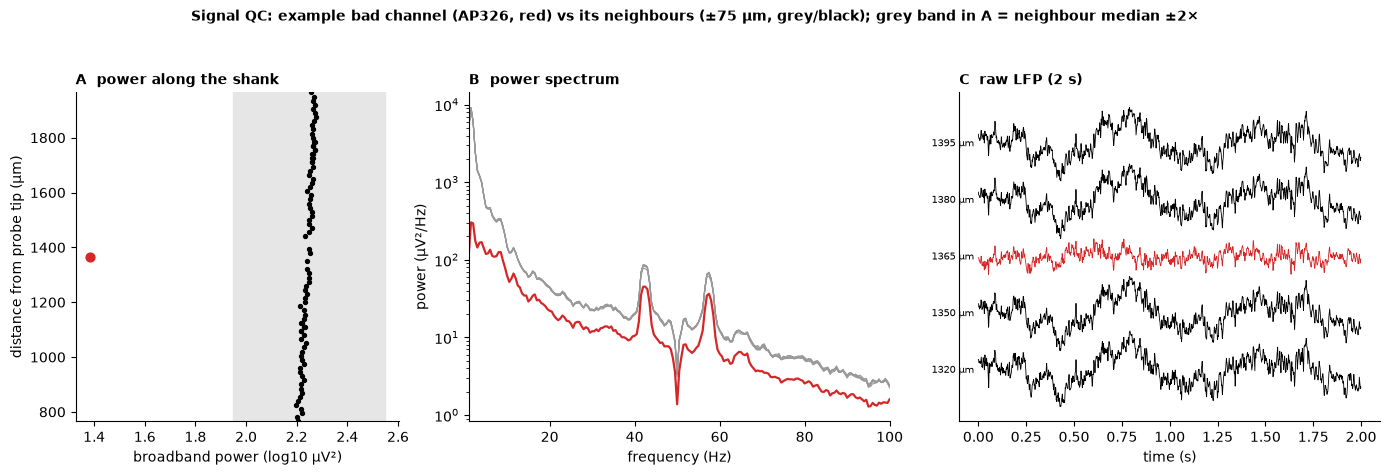

In [17]:
# %%
# ── QC EXAMPLE: one bad channel vs its neighbours (for the slides) ──
SES, BAD = "20260611_r0000135_wt_1415", "AP326"
recs, _ = fn.load_session(PROC, SES, None, refs=("original",))            # NO extra-bad list -> the bad channel is still there
rec = recs["original"]
pdf = fn.probe_table(rec)
pdf["ap"] = pdf["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]
b = pdf[pdf["ap"] == BAD].iloc[0]
sh = pdf[pdf["shank"] == b["shank"]].sort_values("y")                     # all channels on the same shank
nb = sh[(np.abs(sh["y"] - b["y"]) <= 75) & (sh["ap"] != BAD)]             # neighbours ±75 µm (as in the QC rule)

freqs, psd, ids = fn.compute_psd(rec, channel_ids=list(sh["channel_id"]))  # same PSD as the QC (30 × 10 s, 1–100 Hz)
tab = fn.psd_table(freqs, psd, ids, pdf).merge(pdf[["channel_id", "ap"]], on="channel_id")
tab = tab.set_index("channel_id").loc[sh["channel_id"]].reset_index()
med = tab.loc[tab["channel_id"].isin(nb["channel_id"]), "log_broadband"].median()
dev = tab.loc[tab["ap"] == BAD, "log_broadband"].iloc[0] - med
print(f"{SES} {BAD}: broadband log10 power {dev:+.2f} vs median of {len(nb)} neighbours "
      f"(= {10 ** dev:.1f}x; flagged if |Δ| > 0.3 = 2x)")

fig, axs = plt.subplots(1, 3, figsize=(14, 4.8), facecolor="white", gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
# A: broadband power along the shank
ax = axs[0]
ax.axvspan(med - 0.3, med + 0.3, color="0.9", zorder=0)
ax.scatter(tab["log_broadband"], tab["y"], s=8, color="k")
r_ = tab[tab["ap"] == BAD]
ax.scatter(r_["log_broadband"], r_["y"], s=40, color="#d62728", zorder=3)
ax.set_ylim(b["y"] - 600, b["y"] + 600)
ax.set_xlabel("broadband power (log10 µV²)"); ax.set_ylabel("distance from probe tip (µm)")
ax.set_title("A  power along the shank", loc="left", fontsize=10, fontweight="bold")
# B: PSD of the bad channel vs neighbours
ax = axs[1]
idx = {c: i for i, c in enumerate(ids)}
for c in nb["channel_id"]:
    ax.semilogy(freqs, psd[idx[c]], color="0.6", lw=0.8)
ax.semilogy(freqs, psd[idx[b["channel_id"]]], color="#d62728", lw=1.6)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("power (µV²/Hz)"); ax.set_xlim(1, 100)
ax.set_title("B  power spectrum", loc="left", fontsize=10, fontweight="bold")
# C: 2 s of raw signal, bad channel + 4 nearest neighbours
ax = axs[2]
near = nb.iloc[np.argsort(np.abs(nb["y"].values - b["y"]))[:4]]
show = pd.concat([near, pdf[pdf["ap"] == BAD]]).sort_values("y")
fs = rec.get_sampling_frequency(); a = int(rec.get_num_samples() // 2)
X = rec.get_traces(start_frame=a, end_frame=a + int(2 * fs), channel_ids=list(show["channel_id"]), return_in_uV=True).astype(float)
X = X - X.mean(0); step = 4 * np.median(X.std(0)); t = np.arange(X.shape[0]) / fs
for j, (_, ch) in enumerate(show.iterrows()):
    ax.plot(t, X[:, j] + j * step, color="#d62728" if ch["ap"] == BAD else "k", lw=0.6)
    ax.text(-0.02, j * step, f"{int(ch['y'])} µm", ha="right", va="center", fontsize=7)
ax.set_yticks([]); ax.set_xlabel("time (s)")
ax.set_title("C  raw LFP (2 s)", loc="left", fontsize=10, fontweight="bold")


for a_ in axs:
    for sp in ("top", "right"): a_.spines[sp].set_visible(False)
fig.suptitle(f"Signal QC: example bad channel ({BAD}, red) vs its neighbours (±75 µm, grey/black); "
             f"grey band in A = neighbour median ±2×", fontsize=10, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
QC_DIR = os.path.join(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data", "QC")
os.makedirs(QC_DIR, exist_ok=True)
fig.savefig(os.path.join(QC_DIR, "QC example bad channel.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

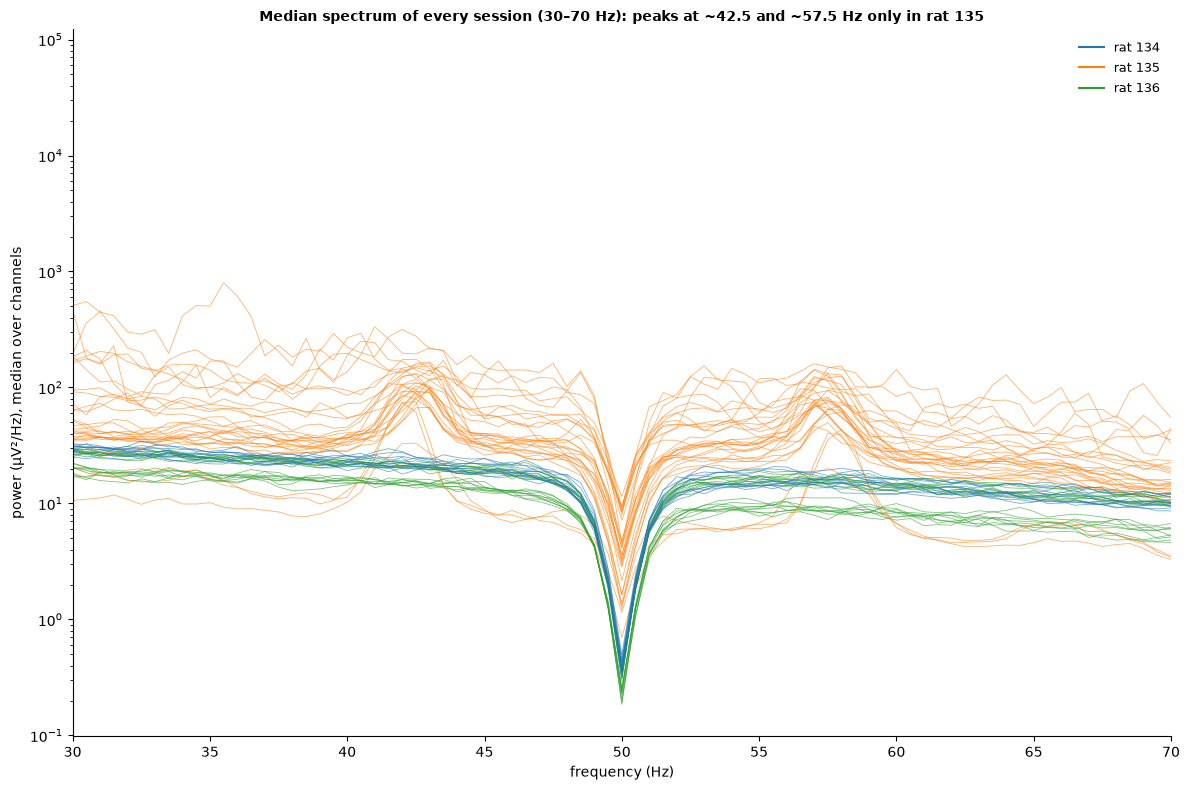

In [5]:
# %%
# ── QC: fixed electrical interference in rat 135 (median spectrum of every session, original) ──
REF = "original"
cols = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}
fig, ax = plt.subplots(figsize=(12, 8), facecolor="white")
for s in final["session"]:
    f = os.path.join(PROC, s, QC_SUB, "psd.npz")
    if not os.path.exists(f):
        continue
    z = np.load(f); rat = final.set_index("session").loc[s, "rat"]
    ax.semilogy(z["freqs"], np.median(z[f"psd_{REF}"], axis=0), color=cols[rat], lw=0.6, alpha=0.6)
ax.set_xlim(30, 70); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("power (µV²/Hz), median over channels")
ax.legend(handles=[plt.Line2D([], [], color=c, label=f"rat {r}") for r, c in cols.items()], frameon=False, fontsize=9)
ax.set_title("Median spectrum of every session (30–70 Hz): peaks at ~42.5 and ~57.5 Hz only in rat 135",
             fontsize=10, fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
QC_DIR = os.path.join(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data", "QC")
os.makedirs(QC_DIR, exist_ok=True)
fig.savefig(os.path.join(QC_DIR, "fixed_electrical_interference_rat_135.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

In [10]:
# %%
# ── QC: find the WORST extra bad channel (deviation from neighbours, original signal) ──
import time
XBs = XB.copy(); XBs["ap"] = XBs["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]
rows = []; t_all = time.time()
for s, g in XBs.groupby("session"):
    try:
        rec = fn.load_session(PROC, s, None, refs=("original",))[0]["original"]       # without the extra-bad list
        pdf = fn.probe_table(rec); pdf["ap"] = pdf["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]
        bad_here = set(g["ap"])
        for ap, reason in zip(g["ap"], g["reason"]):
            b = pdf[pdf["ap"] == ap]
            if b.empty:
                continue                                                               # already removed in preprocessing
            b = b.iloc[0]
            nb = pdf[(pdf["shank"] == b["shank"]) & (np.abs(pdf["y"] - b["y"]) <= 75) & ~pdf["ap"].isin(bad_here)]
            if len(nb) < 3:
                continue
            ch = [b["channel_id"]] + list(nb["channel_id"])
            freqs, psd, ids = fn.compute_psd(rec, channel_ids=ch)
            t = fn.psd_table(freqs, psd, ids, pdf)
            v = t.set_index("channel_id")["log_broadband"]
            rows.append({"session": s, "rat": s.split("_r0000")[1][:3], "channel": ap, "y": b["y"], "shank": b["shank"] + 1,
                         "n_neighbours": len(nb), "dev_log10": v[b["channel_id"]] - v[nb["channel_id"]].median(), "reason": reason})
        print(f"{s}: {len(g)} extra bad channels checked ({time.time() - t_all:.0f} s)", flush=True)
    except Exception as e:
        print(f"{s}: ERROR {e!r}", flush=True)
W = pd.DataFrame(rows); W["abs_dev"] = W["dev_log10"].abs(); W["factor"] = 10 ** W["abs_dev"]
W = W.sort_values("abs_dev", ascending=False)
print("\nmost deviating extra bad channels (|log10 power − neighbour median|):")
print(W.head(15)[["session", "rat", "channel", "shank", "y", "n_neighbours", "dev_log10", "factor", "reason"]].round(2).to_string(index=False))
print("\nper channel (all sessions): median deviation")
print(W.groupby(["rat", "channel"])["dev_log10"].agg(["median", "size"]).round(2).sort_values("median").to_string())

20260510_r0000135_wt_1625: 1 extra bad channels checked (5 s)
20260515_r0000135_wt_1953: 1 extra bad channels checked (9 s)
20260515_r0000135_wt_1957: 1 extra bad channels checked (14 s)
20260517_r0000135_wt_1846: 1 extra bad channels checked (19 s)
20260520_r0000135_wt_1357: 2 extra bad channels checked (24 s)
20260521_r0000135_wt_1309: 2 extra bad channels checked (29 s)
20260522_r0000135_wt_1716: 2 extra bad channels checked (35 s)
20260523_r0000135_wt_1320: 2 extra bad channels checked (40 s)
20260524_r0000135_wt_1944: 2 extra bad channels checked (45 s)
20260525_r0000135_wt_1426: 2 extra bad channels checked (50 s)
20260526_r0000135_wt_1411: 2 extra bad channels checked (55 s)
20260527_r0000135_wt_1217: 2 extra bad channels checked (60 s)
20260528_r0000135_wt_1825: 2 extra bad channels checked (66 s)
20260529_r0000135_wt_1411: 2 extra bad channels checked (66 s)
20260602_r0000135_wt_1715: 3 extra bad channels checked (72 s)
20260603_r0000135_wt_1641: 2 extra bad channels checked (